In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error


In [ ]:
# Step 1: Dataset
np.random.seed(0)
X = np.linspace(-3, 3, 100)
y = np.sin(X) + np.random.randn(100)*0.3

X = X.reshape(-1,1)

In [ ]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)


In [ ]:
# Function to run experiment
def run_experiment(degree, use_ridge=False):
    poly = PolynomialFeatures(degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    if use_ridge:
        model = Ridge(alpha=1.0)
        title = f"Degree {degree} (Ridge)"
    else:
        model = LinearRegression()
        title = f"Degree {degree}"

    model.fit(X_train_poly, y_train)

    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)

    train_error = mean_squared_error(y_train, y_train_pred)
    test_error = mean_squared_error(y_test, y_test_pred)

    print(f"\n{title}")
    print("Train Error:", train_error)
    print("Test Error:", test_error)

    # Plot
    X_plot = np.linspace(-3, 3, 100).reshape(-1,1)
    X_plot_poly = poly.transform(X_plot)
    y_plot = model.predict(X_plot_poly)

    plt.scatter(X, y)
    plt.plot(X_plot, y_plot, color='red')
    plt.title(title)
    plt.show()



Degree 1
Train Error: 0.2825284348010216
Test Error: 0.1941618435962828


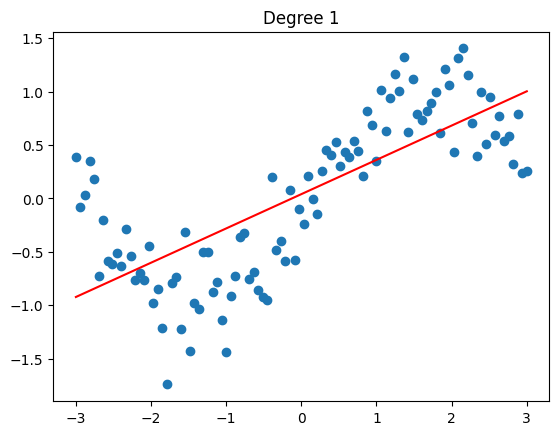


Degree 4
Train Error: 0.07826136472954853
Test Error: 0.07602987214082144


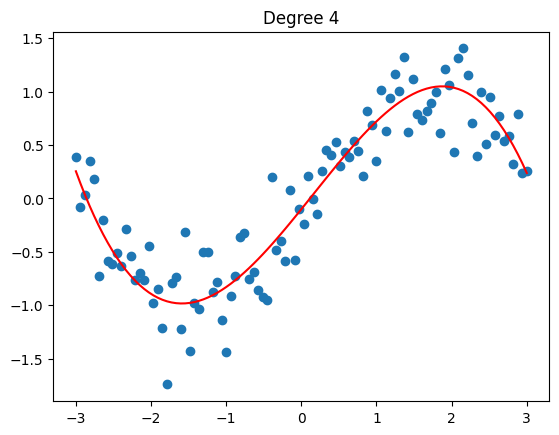


Degree 15
Train Error: 0.0706998163058654
Test Error: 0.10500772392216248


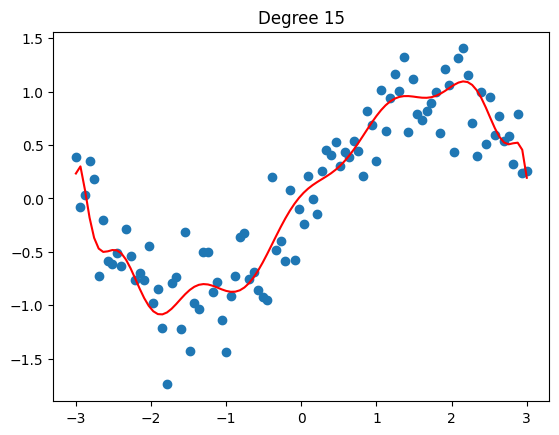


Degree 15 (Ridge)
Train Error: 0.07761008147279974
Test Error: 0.08013201434256906


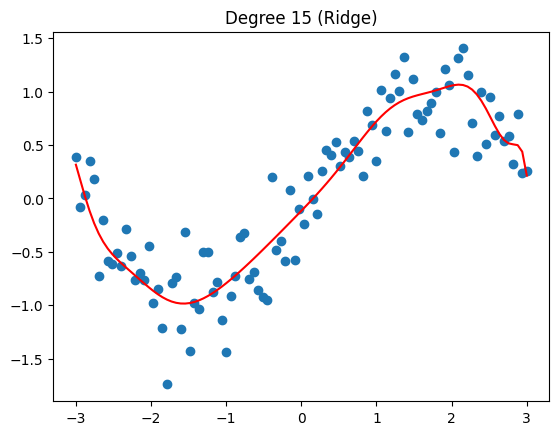

In [ ]:
# Experiments
run_experiment(1)     # Underfitting
run_experiment(4)     # Good Fit
run_experiment(15)    # Overfitting
run_experiment(15, True)  # Ridge (fix overfitting)